# **06 · Entrenamiento de las redes**

Este notebook entrena las iteraciones del modelo. En esta primera parte: la MLP (iteración 1), la búsqueda de hiperparámetros del LSTM y el LSTM base (iteración 2).

Todas las comparaciones se hacen **solo con la validación**. Las pruebas (`test` y `test_season`) se usan una única vez, al final, en el notebook 07; mirarlas ahora para elegir modelos sería ajustar las decisiones a la prueba.

## **0. Configuración**

- **Ventana base:** 14 días, sin el día de la semana como variable. Las iteraciones 3 y 4 cambian cada una de esas dos cosas.
- **Pérdida:** MAE sobre la venta normalizada, solo en días abiertos.
- **Entrenamiento:** Adam (tasa 0.001 salvo en la búsqueda), lotes de 256, dropout de 0.2, parada temprana tras 10 épocas sin mejorar (máximo 100) y checkpoint solo cuando la validación mejora.
- **Semilla:** 123.

In [1]:
import json
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src.baselines import same_weekday_mean, seasonal_naive
from src.metrics import evaluate
from src.models import MLP, LSTMForecaster
from src.training import DEVICE, pinball_loss, predict, train
from src.windows import make_windows

MODELS, RESULTS = ROOT / "models", ROOT / "results"
MODELS.mkdir(exist_ok=True)
RESULTS.mkdir(exist_ok=True)
LOOKBACK, SEED = 14, 123
print("Dispositivo:", DEVICE)

Dispositivo: mps


## **1. Ventanas**

- **Entrenamiento y validación para la red:** ventanas de 14 días cuyos 7 días a predecir están en `train` o en `val`.
- **Validación para comparar:** las mismas ventanas de validación, pero empezando desde el día 28 de cada serie, para medir sobre los mismos días que las líneas base y que la ventana de 28 días.

In [2]:
df = pd.read_parquet(ROOT / "data" / "processed" / "unified.parquet")

train_w = make_windows(df, LOOKBACK, ["train"])
val_w = make_windows(df, LOOKBACK, ["val"])
val_eval = make_windows(df, LOOKBACK, ["val"], first_offset=28)
naive = seasonal_naive(val_eval)

print(f"Entrenamiento: {len(train_w):,} | Validación: {len(val_w):,} | Validación para comparar: {len(val_eval):,}")

Entrenamiento: 115,460 | Validación: 11,438 | Validación para comparar: 11,438


In [3]:
def val_metrics(model):
    prediction = predict(model, val_eval)[..., 0]
    return evaluate(val_eval, prediction, naive)


def plot_history(history, title):
    h = pd.DataFrame(history)
    fig, ax = plt.subplots(figsize=(8, 3.5))
    ax.plot(h["epoch"], h["train_loss"], label="entrenamiento")
    ax.plot(h["epoch"], h["val_loss"], label="validación")
    best = h.loc[h["val_loss"].idxmin()]
    ax.axvline(best["epoch"], color="gray", linestyle="--", linewidth=0.8, label=f"mejor época ({int(best['epoch'])})")
    ax.set_xlabel("Época")
    ax.set_ylabel("MAE normalizado")
    ax.set_title(title)
    ax.legend()
    plt.show()


baselines = pd.read_csv(RESULTS / "00_lineas_base.csv")
best_baseline = baselines[(baselines["modelo"] == "Promedio de los mismos días") & (baselines["ventana"] == 28) & (baselines["split"].isin(["val", "Total"]))]
best_baseline

,split,dataset,predicciones,MAE,RMSE,WAPE,MAE relativo,modelo,ventana,iteracion
21,val,ddop,48279,17.771069,32.954809,0.202575,0.803536,Promedio de los mismos días,28,0
22,val,french_bakery,26824,4.208057,13.973205,0.398357,0.814126,Promedio de los mismos días,28,0
23,Total,NaN,222286,15.372567,32.083246,0.195571,0.832021,Promedio de los mismos días,28,0


## **2. Iteración 1: MLP**

La red más simple: aplana los 14 días × 4 datos y el calendario de los 7 días a predecir en una fila de números, y la pasa por dos capas densas (128 y 64 neuronas) hasta las 7 salidas.

Épocas: 52 | Tiempo: 0.0 min | Parámetros: 18,695


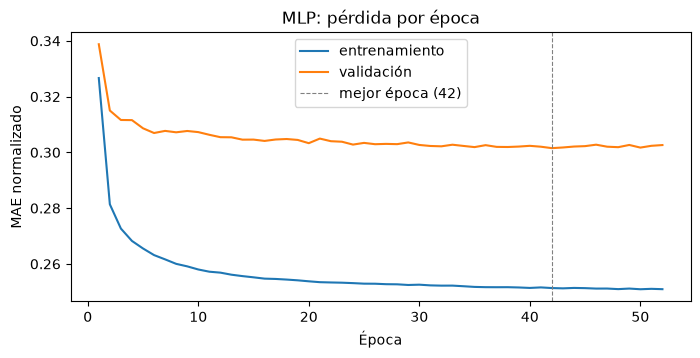

In [4]:
start = time.perf_counter()
mlp = MLP(LOOKBACK, past_features=4, future_features=3)
mlp_history = train(mlp, train_w, val_w, MODELS / "01_mlp.pt", seed=SEED, resume=True)
mlp_minutes = (time.perf_counter() - start) / 60
print(f"Épocas: {len(mlp_history)} | Tiempo: {mlp_minutes:.1f} min | Parámetros: {sum(p.numel() for p in mlp.parameters()):,}")
plot_history(mlp_history, "MLP: pérdida por época")

In [5]:
mlp_metrics = val_metrics(mlp)
mlp_metrics.round(3)

predicciones     MAE    RMSE  WAPE  MAE relativo
split dataset                                                        
val   ddop                  48279  17.554  32.073  0.20         0.794
      french_bakery         26824   3.697  12.736  0.35         0.715
Total                       75103  12.605  26.818  0.21         0.785

## **3. Búsqueda de hiperparámetros del LSTM**

Se prueban 18 combinaciones: 1, 2 o 3 capas de LSTM, 32, 64 o 128 neuronas por capa, y una tasa de aprendizaje de 0.001 o 0.0005. Se elige la de menor WAPE en validación, y esa configuración queda fija para las iteraciones siguientes, de forma que cada iteración cambie una sola cosa.

Cada combinación guarda su checkpoint y su historial, y el resumen se va escribiendo en `results/02_busqueda_lstm.csv`, así que si la búsqueda se interrumpe se puede retomar sin repetir lo ya entrenado.

In [6]:
SEARCH = RESULTS / "02_busqueda_lstm.csv"
done = pd.read_csv(SEARCH) if SEARCH.exists() else pd.DataFrame()
rows = done.to_dict("records")

for layers in (1, 2, 3):
    for hidden in (32, 64, 128):
        for lr in (1e-3, 5e-4):
            name = f"lstm_l{layers}_h{hidden}_lr{lr:g}"
            if any(r["nombre"] == name for r in rows):
                continue
            start = time.perf_counter()
            model = LSTMForecaster(past_features=4, future_features=3, hidden=hidden, layers=layers)
            history = train(model, train_w, val_w, MODELS / "search" / f"{name}.pt", lr=lr, seed=SEED)
            total = val_metrics(model).loc[("Total", "")]
            rows.append({
                "nombre": name, "capas": layers, "neuronas": hidden, "tasa": lr,
                "épocas": len(history), "mejor época": int(pd.DataFrame(history)["val_loss"].idxmin()) + 1,
                "minutos": (time.perf_counter() - start) / 60,
                "parámetros": sum(p.numel() for p in model.parameters()),
                "WAPE val": total["WAPE"], "MAE val": total["MAE"], "MAE relativo val": total["MAE relativo"],
            })
            (MODELS / "search" / f"{name}.json").write_text(json.dumps(history))
            pd.DataFrame(rows).to_csv(SEARCH, index=False)
            print(f"{name}: WAPE {total['WAPE']:.3f} en {len(history)} épocas")

search = pd.DataFrame(rows).sort_values("WAPE val")
search.round(4)

,nombre,capas,neuronas,tasa,épocas,mejor época,minutos,parámetros,WAPE val,MAE val,MAE relativo val
6,lstm_l2_h32_lr0.001,2,32,0.0010,63,53,1.6988,17223,0.2088,12.5642,0.7822
8,lstm_l2_h64_lr0.001,2,64,0.0010,43,33,1.3647,57159,0.2092,12.5841,0.7834
5,lstm_l1_h128_lr0.0005,1,128,0.0005,42,32,2.0641,78663,0.2095,12.6044,0.7847
9,lstm_l2_h64_lr0.0005,2,64,0.0005,47,37,1.5796,57159,0.2097,12.6144,0.7853
7,lstm_l2_h32_lr0.0005,2,32,0.0005,63,53,1.9475,17223,0.2098,12.6246,0.7859
10,lstm_l2_h128_lr0.001,2,128,0.0010,28,18,1.8059,210759,0.2101,12.6405,0.7869
13,lstm_l3_h32_lr0.0005,3,32,0.0005,69,59,1.9078,25671,0.2102,12.6491,0.7874
12,lstm_l3_h32_lr0.001,3,32,0.0010,63,53,1.9548,25671,0.2103,12.6515,0.7876
0,lstm_l1_h32_lr0.001,1,32,0.0010,50,40,1.3967,8775,0.2105,12.6626,0.7883
15,lstm_l3_h64_lr0.0005,3,64,0.0005,47,37,2.3695,90439,0.2112,12.7078,0.7911


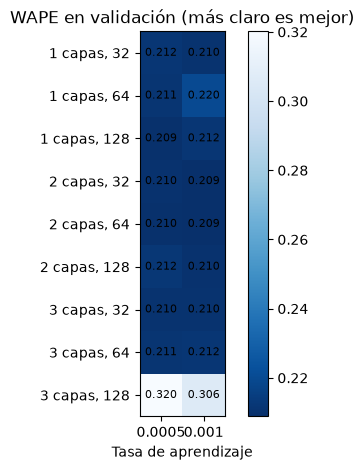

In [7]:
pivot = search.pivot_table(index=["capas", "neuronas"], columns="tasa", values="WAPE val")
fig, ax = plt.subplots(figsize=(6, 5))
image = ax.imshow(pivot.values, cmap="Blues_r")
ax.set_xticks(range(len(pivot.columns)), [f"{c:g}" for c in pivot.columns])
ax.set_yticks(range(len(pivot.index)), [f"{l} capas, {h}" for l, h in pivot.index])
for (i, j), value in pd.DataFrame(pivot.values).stack().items():
    ax.text(j, i, f"{value:.3f}", ha="center", va="center", fontsize=8)
ax.set_xlabel("Tasa de aprendizaje")
ax.set_title("WAPE en validación (más claro es mejor)")
plt.colorbar(image)
plt.show()

## **4. Iteración 2: LSTM base**

El LSTM base es la combinación con menor WAPE en validación. Su checkpoint ya quedó guardado durante la búsqueda, así que solo se carga.

Configuración elegida: 2 capas, 32 neuronas, tasa 0.001


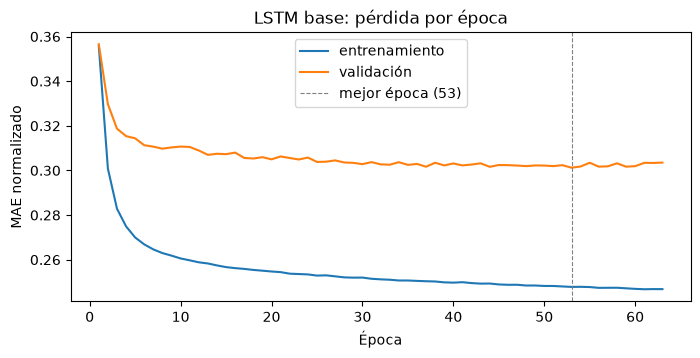

In [8]:
best = search.iloc[0]
lstm = LSTMForecaster(past_features=4, future_features=3, hidden=int(best["neuronas"]), layers=int(best["capas"]))
checkpoint = MODELS / "search" / f"{best['nombre']}.pt"
lstm.load_state_dict(torch.load(checkpoint, map_location=DEVICE))
lstm.to(DEVICE)
(MODELS / "02_lstm_base.pt").write_bytes(checkpoint.read_bytes())

lstm_history = json.loads((MODELS / "search" / f"{best['nombre']}.json").read_text())
print(f"Configuración elegida: {best['capas']} capas, {best['neuronas']} neuronas, tasa {best['tasa']:g}")
plot_history(lstm_history, "LSTM base: pérdida por época")

In [9]:
lstm_metrics = val_metrics(lstm)
lstm_metrics.round(3)

predicciones     MAE    RMSE   WAPE  MAE relativo
split dataset                                                         
val   ddop                  48279  17.536  31.622  0.200         0.793
      french_bakery         26824   3.616  12.288  0.342         0.700
Total                       75103  12.564  26.395  0.209         0.782

## **5. Comparación en validación**

In [10]:
rows = []
for name, table in [
    ("Igual que la semana pasada", evaluate(val_eval, naive, naive)),
    ("Promedio de los mismos días (28)", evaluate(make_windows(df, 28, ["val"], first_offset=28), same_weekday_mean(make_windows(df, 28, ["val"], first_offset=28)), naive)),
    ("MLP (iteración 1)", mlp_metrics),
    ("LSTM base (iteración 2)", lstm_metrics),
]:
    rows.append(table.reset_index().assign(modelo=name))
comparison = pd.concat(rows, ignore_index=True)
comparison["dataset"] = comparison["dataset"].replace("", "Total").fillna("Total")
comparison.pivot_table(index="modelo", columns="dataset", values="WAPE", sort=False).round(3)

dataset,ddop,french_bakery,Total
modelo,,,
Igual que la semana pasada,0.252,0.489,0.267
Promedio de los mismos días (28),0.203,0.398,0.215
MLP (iteración 1),0.200,0.350,0.210
LSTM base (iteración 2),0.200,0.342,0.209


**Conclusiones de las iteraciones 1 y 2:**

- **Las dos redes le ganan a la mejor línea base, sobre todo en French Bakery.** El WAPE en validación baja de 39.8 % (promedio de los mismos días) a 34.2 % con el LSTM, un 14 % menos de error. En ddop la mejora es mínima (20.3 % a 20.0 %): con 3 productos muy regulares, promediar los mismos días ya es casi lo mejor posible, mientras que en French Bakery, con 47 productos de comportamientos distintos, la red aprende algo que el promedio no ve.
- **El LSTM y la MLP casi empatan** (20.9 % y 21.0 % en total). Con una ventana de 14 días, leer los días en orden aporta poco frente a verlos todos juntos; la iteración con 28 días mostrará si el orden pesa más en una secuencia más larga.
- **Las curvas no muestran sobreajuste:** el error de validación se aplana tras unas 10 épocas y no vuelve a subir. La brecha entre entrenamiento y validación es esperable, porque la validación es un periodo distinto.
- **Búsqueda de hiperparámetros:** ganó la configuración de 2 capas y 32 neuronas con tasa 0.001, una de las más pequeñas (17 mil pesos). 16 de las 18 combinaciones quedaron entre 20.9 % y 22.0 % de WAPE, y las diferencias entre las mejores son de centésimas de punto, del mismo orden que la variación por semilla; con otra semilla podría ganar otra combinación cercana. La red más grande (3 capas de 128) fue la peor (30.6 % y 32.0 %): más capacidad no mejora con estos datos, y su pérdida normalizada parecida a la de las demás no se tradujo en buen error en unidades, posiblemente por fallar en las series de mayor volumen.

## **6. Guardar resultados**

In [11]:
for iteration, name, table in [(1, "MLP", mlp_metrics), (2, "LSTM base", lstm_metrics)]:
    table.reset_index().assign(iteracion=iteration, modelo=name, ventana=LOOKBACK).to_csv(RESULTS / f"0{iteration}_{name.lower().replace(' ', '_')}.csv", index=False)
(MODELS / "01_mlp.json").write_text(json.dumps(mlp_history))
print("Resultados guardados en results/")

Resultados guardados en results/


## **7. Iteración 3: ventana de 28 días**

El mismo LSTM base (mismos hiperparámetros), con una sola diferencia: ve 4 semanas hacia atrás en lugar de 2. La autocorrelación del análisis exploratorio tuvo picos en 7, 14, 21 y 28 días, así que con 28 días la red ve cada día de la semana 4 veces en lugar de 2.

La validación para comparar usa los mismos días que el resto (`first_offset=28`).

Épocas: 43 | Tiempo: 0.0 min


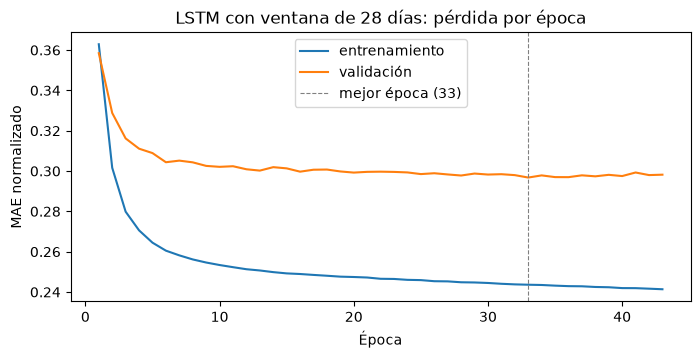

In [12]:
best_config = dict(hidden=int(best["neuronas"]), layers=int(best["capas"]))
best_lr = float(best["tasa"])

train_28 = make_windows(df, 28, ["train"])
val_28 = make_windows(df, 28, ["val"])
val_eval_28 = make_windows(df, 28, ["val"], first_offset=28)
assert val_eval_28.meta[["product_id", "first_date"]].equals(val_eval.meta[["product_id", "first_date"]]), "No se compara sobre los mismos días"

start = time.perf_counter()
lstm_28 = LSTMForecaster(past_features=4, future_features=3, **best_config)
lstm_28_history = train(lstm_28, train_28, val_28, MODELS / "03_lstm_28.pt", lr=best_lr, seed=SEED, resume=True)
print(f"Épocas: {len(lstm_28_history)} | Tiempo: {(time.perf_counter() - start) / 60:.1f} min")
plot_history(lstm_28_history, "LSTM con ventana de 28 días: pérdida por época")

In [13]:
lstm_28_metrics = evaluate(val_eval_28, predict(lstm_28, val_eval_28)[..., 0], naive)
lstm_28_metrics.round(3)

predicciones     MAE    RMSE   WAPE  MAE relativo
split dataset                                                         
val   ddop                  48279  17.073  31.183  0.195         0.785
      french_bakery         26824   3.567  12.231  0.338         0.715
Total                       75103  12.249  26.049  0.204         0.777

## **8. Iteración 4: día de la semana como variable**

El mismo LSTM base con ventana de 14 días, con una sola diferencia: cada día de la entrada y de la salida lleva su día de la semana, codificado como seno y coseno.

La hipótesis es doble: el día de la semana podría ayudar a la red a ubicarse dentro de la semana, pero también podría hacer que aprenda "los domingos se vende más" de ddop y French Bakery y lo aplique mal a un negocio con otro patrón, como The Bread Basket, cuyo pico es el sábado. La validación solo tiene ddop y French Bakery, así que podría favorecer esta versión; la respuesta para un negocio distinto se verá en la prueba.

Épocas: 58 | Tiempo: 0.0 min


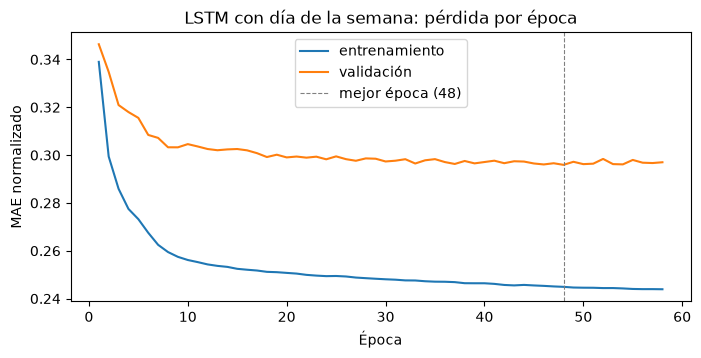

In [14]:
train_dow = make_windows(df, LOOKBACK, ["train"], use_day_of_week=True)
val_dow = make_windows(df, LOOKBACK, ["val"], use_day_of_week=True)
val_eval_dow = make_windows(df, LOOKBACK, ["val"], use_day_of_week=True, first_offset=28)

start = time.perf_counter()
lstm_dow = LSTMForecaster(past_features=6, future_features=5, **best_config)
lstm_dow_history = train(lstm_dow, train_dow, val_dow, MODELS / "04_lstm_dia_semana.pt", lr=best_lr, seed=SEED, resume=True)
print(f"Épocas: {len(lstm_dow_history)} | Tiempo: {(time.perf_counter() - start) / 60:.1f} min")
plot_history(lstm_dow_history, "LSTM con día de la semana: pérdida por época")

In [15]:
lstm_dow_metrics = evaluate(val_eval_dow, predict(lstm_dow, val_eval_dow)[..., 0], naive)
lstm_dow_metrics.round(3)

predicciones     MAE    RMSE   WAPE  MAE relativo
split dataset                                                         
val   ddop                  48279  17.298  31.378  0.197         0.782
      french_bakery         26824   3.573  12.003  0.338         0.691
Total                       75103  12.396  26.160  0.206         0.772

## **9. Comparación de las iteraciones en validación**

In [16]:
all_iterations = pd.concat([
    comparison,
    lstm_28_metrics.reset_index().assign(modelo="LSTM 28 días (iteración 3)"),
    lstm_dow_metrics.reset_index().assign(modelo="LSTM con día de la semana (iteración 4)"),
], ignore_index=True)
all_iterations["dataset"] = all_iterations["dataset"].replace("", "Total").fillna("Total")
all_iterations.pivot_table(index="modelo", columns="dataset", values="WAPE", sort=False).round(3)

dataset,ddop,french_bakery,Total
modelo,,,
Igual que la semana pasada,0.252,0.489,0.267
Promedio de los mismos días (28),0.203,0.398,0.215
MLP (iteración 1),0.200,0.350,0.210
LSTM base (iteración 2),0.200,0.342,0.209
LSTM 28 días (iteración 3),0.195,0.338,0.204
LSTM con día de la semana (iteración 4),0.197,0.338,0.206


In [17]:
for iteration, name, table, lookback in [(3, "LSTM 28 dias", lstm_28_metrics, 28), (4, "LSTM dia semana", lstm_dow_metrics, LOOKBACK)]:
    table.reset_index().assign(iteracion=iteration, modelo=name, ventana=lookback).to_csv(RESULTS / f"0{iteration}_{name.lower().replace(' ', '_')}.csv", index=False)
for name, history in [("03_lstm_28", lstm_28_history), ("04_lstm_dia_semana", lstm_dow_history)]:
    (MODELS / f"{name}.json").write_text(json.dumps(history))
print("Resultados guardados en results/")

Resultados guardados en results/


## **10. Confirmación con tres semillas**

Las diferencias entre el LSTM base y las iteraciones 3 y 4 son de medio punto de WAPE, y la misma red con la misma semilla puede variar unas décimas entre corridas en la GPU del Mac. Para saber si las mejoras se deben al diseño y no al azar, cada versión se entrena también con las semillas 2026 y 56, y se reporta el promedio y la desviación estándar de las tres.

In [18]:
versions = {
    "LSTM base (iteración 2)": dict(lookback=LOOKBACK, use_day_of_week=False, eval_w=val_eval, metrics_123=lstm_metrics),
    "LSTM 28 días (iteración 3)": dict(lookback=28, use_day_of_week=False, eval_w=val_eval_28, metrics_123=lstm_28_metrics),
    "LSTM con día de la semana (iteración 4)": dict(lookback=LOOKBACK, use_day_of_week=True, eval_w=val_eval_dow, metrics_123=lstm_dow_metrics),
}

SEEDS_FILE = RESULTS / "02_04_semillas.csv"
seed_rows = []
for name, v in ([] if SEEDS_FILE.exists() else versions.items()):
    seed_rows.append(v["metrics_123"].reset_index().assign(modelo=name, semilla=123))
    tr = make_windows(df, v["lookback"], ["train"], use_day_of_week=v["use_day_of_week"])
    va = make_windows(df, v["lookback"], ["val"], use_day_of_week=v["use_day_of_week"])
    features = (6, 5) if v["use_day_of_week"] else (4, 3)
    for seed in (2026, 56):
        model = LSTMForecaster(past_features=features[0], future_features=features[1], **best_config)
        slug = name.split("(")[1].rstrip(")").replace(" ", "_").replace("ó", "o")
        train(model, tr, va, MODELS / "seeds" / f"{slug}_seed{seed}.pt", lr=best_lr, seed=seed, resume=True)
        metrics = evaluate(v["eval_w"], predict(model, v["eval_w"])[..., 0], naive)
        seed_rows.append(metrics.reset_index().assign(modelo=name, semilla=seed))
        print(f"{name}, semilla {seed}: WAPE total {metrics.loc[('Total', ''), 'WAPE']:.4f}")

if SEEDS_FILE.exists():
    seeds = pd.read_csv(SEEDS_FILE)  # ya se entrenaron; volver a correr el notebook no cambia los resultados
else:
    seeds = pd.concat(seed_rows, ignore_index=True)
    seeds["dataset"] = seeds["dataset"].replace("", "Total").fillna("Total")
    seeds.to_csv(SEEDS_FILE, index=False)

In [19]:
summary = seeds.groupby(["modelo", "dataset"], sort=False)["WAPE"].agg(["mean", "std"]).unstack("dataset")
summary.columns = [f"{dataset} ({stat})" for stat, dataset in summary.columns]
(summary * 100).round(2)

,ddop (mean),french_bakery (mean),Total (mean),ddop (std),french_bakery (std),Total (std)
modelo,,,,,,
LSTM base (iteración 2),20.01,34.40,20.91,0.03,0.19,0.04
LSTM 28 días (iteración 3),19.46,34.18,20.38,0.01,0.35,0.02
LSTM con día de la semana (iteración 4),19.77,33.62,20.64,0.08,0.24,0.06


In [20]:
totals = seeds[seeds["dataset"] == "Total"].pivot_table(index="semilla", columns="modelo", values="WAPE", sort=False)
(totals * 100).round(2)

modelo,LSTM base (iteración 2),LSTM 28 días (iteración 3),LSTM con día de la semana (iteración 4)
semilla,,,
123,20.88,20.36,20.60
2026,20.90,20.39,20.71
56,20.95,20.38,20.60


**Conclusiones de las iteraciones 3 y 4:**

- **La ventana de 28 días es la mejor configuración:** baja el WAPE total de validación de 20.91 % a 20.38 % en promedio, y gana en las tres semillas. La mejora (unos 0.53 puntos) es unas 15 veces mayor que la variación entre semillas (0.02 a 0.04 puntos), así que se debe al diseño y no al azar. Coincide con la autocorrelación: ver cada día de la semana 4 veces en lugar de 2 ayuda.
- **El día de la semana también mejora en las tres semillas, pero la mitad** (20.64 % en promedio), y su ganancia está en French Bakery. La validación solo tiene negocios con pico el domingo, así que esta mejora todavía no dice si el día de la semana se traslada a un negocio con otro patrón; se evaluará en The Bread Basket en el notebook 07.
- **La variación por semilla es menor a 0.1 puntos** en todas las versiones, así que los resultados son estables pese a los factores aleatorios del entrenamiento (pesos iniciales, orden de los lotes y dropout).
- **La iteración 5 parte del LSTM con ventana de 28 días y sin día de la semana**, la mejora más grande y robusta. Así, si los cuantiles cambian el resultado en la prueba, no se confunde con el efecto del día de la semana.

## **11. Iteración 5: pérdida por cuantiles**

El LSTM con ventana de 28 días (iteración 3), con una sola diferencia: en lugar de un número por día, predice 9 cuantiles, del 0.50 al 0.90 de 5 en 5, y se entrena con la pérdida por cuantiles. Para el cuantil q, quedarse corto se castiga con peso q y pasarse con peso 1 − q, así que cada salida aprende a apuntar más o menos alto.

Los q* de los productos que se producen por adelantado están entre 0.65 y 0.80, así que la escalera los cubre con margen. Al decidir cuánto producir, se toma el escalón más cercano al q* de cada producto. El valor en dinero se calcula en el notebook 07; aquí se revisa que la mediana siga siendo buena y que los cuantiles estén calibrados.

Épocas: 43 | Tiempo: 0.0 min


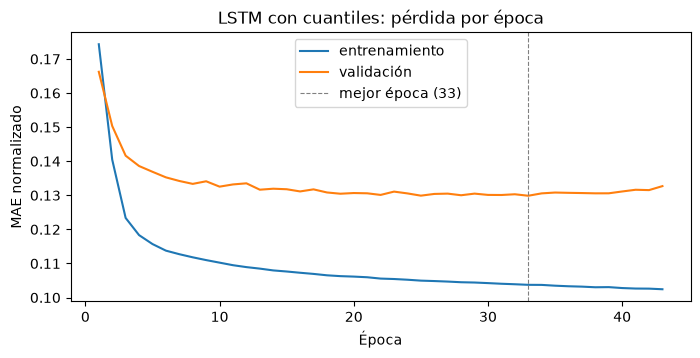

In [21]:
QUANTILES = [0.5, 0.55, 0.6, 0.65, 0.7, 0.75, 0.8, 0.85, 0.9]

start = time.perf_counter()
lstm_q = LSTMForecaster(past_features=4, future_features=3, quantiles=len(QUANTILES), **best_config)
lstm_q_history = train(lstm_q, train_28, val_28, MODELS / "05_lstm_cuantiles.pt", loss_fn=pinball_loss, quantiles=QUANTILES, lr=best_lr, seed=SEED, resume=True)
print(f"Épocas: {len(lstm_q_history)} | Tiempo: {(time.perf_counter() - start) / 60:.1f} min")
plot_history(lstm_q_history, "LSTM con cuantiles: pérdida por época")

**¿La mediana sigue siendo buena?** El cuantil 0.50 se compara en WAPE contra la iteración 3.

In [22]:
q_prediction = predict(lstm_q, val_eval_28)
lstm_q_metrics = evaluate(val_eval_28, q_prediction[..., 0], naive)
median_check = pd.concat([lstm_28_metrics.assign(modelo="Iteración 3 (MAE)"), lstm_q_metrics.assign(modelo="Iteración 5, cuantil 0.50")]).reset_index()
median_check["dataset"] = median_check["dataset"].replace("", "Total")
median_check.pivot_table(index="modelo", columns="dataset", values="WAPE", sort=False).round(4)

dataset,ddop,french_bakery,Total
modelo,,,
Iteración 3 (MAE),0.1946,0.3377,0.2036
"Iteración 5, cuantil 0.50",0.1960,0.3375,0.2048


**¿Los cuantiles dicen la verdad? (calibración)** Para cada cuantil, el porcentaje de días en que la venta real quedó por debajo de lo predicho. Si la red está bien calibrada, el cuantil 0.80 debería cubrir cerca del 80 % de los días.

In [23]:
scale = val_eval_28.scale[:, None]
actual = (val_eval_28.target * scale)[val_eval_28.mask == 1]
coverage = {}
for i, q in enumerate(QUANTILES):
    predicted = (q_prediction[..., i] * scale)[val_eval_28.mask == 1]
    coverage[q] = (actual <= predicted).mean()
calibration = pd.DataFrame({"cuantil": QUANTILES, "cobertura real": list(coverage.values())})
calibration["diferencia"] = calibration["cobertura real"] - calibration["cuantil"]
calibration.round(3)

,cuantil,cobertura real,diferencia
0,0.50,0.499,-0.001
1,0.55,0.546,-0.004
2,0.60,0.591,-0.009
3,0.65,0.639,-0.011
4,0.70,0.691,-0.009
5,0.75,0.740,-0.010
6,0.80,0.788,-0.012
7,0.85,0.838,-0.012
8,0.90,0.887,-0.013


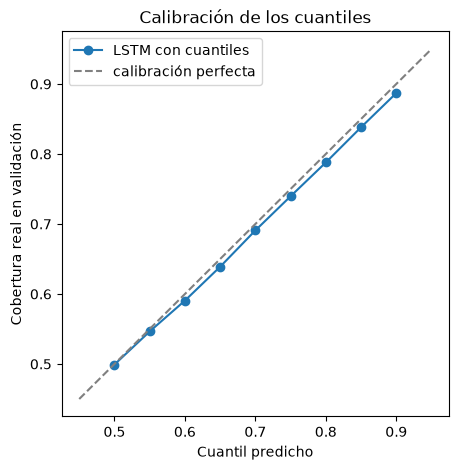

Escalones fuera de orden (un cuantil por debajo del anterior): 0.01%


In [24]:
fig, ax = plt.subplots(figsize=(5, 5))
ax.plot(QUANTILES, calibration["cobertura real"], marker="o", label="LSTM con cuantiles")
ax.plot([0.45, 0.95], [0.45, 0.95], color="gray", linestyle="--", label="calibración perfecta")
ax.set_xlabel("Cuantil predicho")
ax.set_ylabel("Cobertura real en validación")
ax.set_title("Calibración de los cuantiles")
ax.legend()
plt.show()

crossings = (np.diff(q_prediction, axis=-1) < 0).mean()
print(f"Escalones fuera de orden (un cuantil por debajo del anterior): {crossings:.2%}")

**Conclusiones de la iteración 5:**

- **La mediana casi no empeora:** el cuantil 0.50 tiene un WAPE de 20.48 % en validación, frente a 20.36 % de la iteración 3. La escalera de cuantiles se gana casi sin perder precisión.
- **Los cuantiles están bien calibrados:** cada cuantil cubre entre 0.4 y 1.3 puntos menos de lo que indica (por ejemplo, el 0.80 cubre el 78.8 % de los días). La red es apenas optimista, así que una recomendación basada en ella quedaría ligeramente corta; la diferencia es pequeña y no se corrige, pero se reporta como limitación.
- **Casi no hay cuantiles fuera de orden** (0.01 % de las predicciones), así que no hace falta reordenarlos.
- **El valor de esta iteración se mide en dinero en el notebook 07,** donde cada producto usa el cuantil más cercano a su q*.

In [25]:
lstm_q_metrics.reset_index().assign(iteracion=5, modelo="LSTM cuantiles", ventana=28).to_csv(RESULTS / "05_lstm_cuantiles.csv", index=False)
calibration.to_csv(RESULTS / "05_calibracion.csv", index=False)
print("Resultados guardados en results/")

Resultados guardados en results/
